# 03 — Modelo final B (solo TCP): evaluación, ablaciones y exportación

Tercer notebook de tres. Entrena el modelo elegido en `02_tcp_vs_mqtt.ipynb`:
**XGBoost con las 12 features TCP** (`data_preprocessing/tcp_features.py`), con
hiperparámetros fijos y `sample_weight` balanceado (`evaluation/`).

**Alcance de entrenamiento: vista `mqtt`** (frames con puerto 1883/8883 en origen o
destino). El agente se despliega junto al broker y lo que clasifica es ese tráfico. El
normal no-MQTT no se borra del dataset; simplemente no entra al entrenamiento, porque
enseña un atajo ("no va al broker ⇒ normal") que no sirve en despliegue. La sección 4
lo demuestra comparando con el mismo modelo entrenado sobre todo el tráfico.

1. Carga del artefacto y features TCP de la vista `mqtt`.
2. Evaluación con `StratifiedGroupKFold` por `_connection`.
3. Ablaciones de B (antes 2.10/2.11) y AUC univariada.
4. Por qué no entrenar con todo el tráfico.
5. Refit sobre la vista `mqtt`, exportación a `modelos_agente_tcp/` y validación.

`modelos_agente/` **no se modifica** aquí: el agente actual espera artefactos MQTT.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

SEED = 42


def find_repo_root(start=None):
    """Sube desde el cwd hasta la carpeta que contiene `dataset/` y `ML_Model/`."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'dataset').is_dir() and (candidate / 'ML_Model').is_dir():
            return candidate
    raise FileNotFoundError(f'No se encontró la raíz del repositorio desde {start}')


REPO_ROOT = find_repo_root()
MODEL_CODE_DIR = REPO_ROOT / 'ML_Model'
MODEL_DIR = REPO_ROOT / 'modelos_agente_tcp'
if str(MODEL_CODE_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_CODE_DIR))

# Re-ejecutar en el mismo kernel recarga los paquetes locales.
for name in [m for m in sys.modules
             if m.split('.')[0] in ('data_preprocessing', 'evaluation', 'export')]:
    del sys.modules[name]

from data_preprocessing.artifacts import CONTEXT_ONLY_COLUMNS, load_clean_artifact
from data_preprocessing.load_data import TARGET_COL
from data_preprocessing.mqtt_features import build_feature_matrix
from data_preprocessing.tcp_features import (TCP_FEATURE_COLUMNS, WINDOW_SECONDS,
                                             build_tcp_features)
import evaluation as ev
import export

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

## 1. Datos y features TCP

Se carga `df_raw` (con verificación de hash) y se filtra la vista `mqtt`. Las features
TCP se calculan **solo con los frames de la vista**, igual que las verá el agente: las
ventanas causales de 5 s no incluyen tráfico de otros servicios.

IP, puertos crudos y `frame.time_epoch` solo son claves de agrupación/orden. Etiqueta
binaria: `normal = 0`, `ataque (DoS) = 1`.

In [2]:
df_raw, source_manifest = load_clean_artifact(MODEL_CODE_DIR / 'artifacts')
assert set(df_raw[TARGET_COL]) == {'normal', 'DoS'}
assert {'_connection', '_direction', '_capture', *CONTEXT_ONLY_COLUMNS} <= set(df_raw.columns)

df_train = ev.mqtt_scope(df_raw)
frames, connections = ev.scope_overview(df_train)
print(f'df_raw: {df_raw.shape} -> vista mqtt: {df_train.shape} '
      f'({len(df_train) / len(df_raw):.1%} de los frames, '
      f'{df_train[TARGET_COL].eq("DoS").sum() / df_raw[TARGET_COL].eq("DoS").sum():.1%} del DoS)')
display(frames)
display(connections)

df_raw: (257457, 21) -> vista mqtt: (61654, 21) (23.9% de los frames, 99.7% del DoS)


type,DoS,normal,total
_capture,,,
DoS,45330,969,46299
Intrusion,0,7700,7700
MitM,0,7655,7655
total,45330,16324,61654


type,DoS,normal
_capture,,
DoS,886,41
Intrusion,0,368
MitM,0,23
total,886,432


In [3]:
X_tcp = build_tcp_features(df_train)
y = ev.binary_labels(df_train)
captures = df_train['_capture'].to_numpy()
groups = pd.factorize(df_train['_connection'], sort=False)[0]

assert list(X_tcp.columns) == TCP_FEATURE_COLUMNS and X_tcp.shape[1] == 12
assert np.isfinite(X_tcp.to_numpy()).all()
assert not set(X_tcp.columns) & {'ip.src', 'ip.dst', 'tcp.srcport', 'tcp.dstport',
                                 'frame.time_epoch'}
assert not any(c.startswith('mqtt.') for c in X_tcp.columns)
print(f'X_tcp: {X_tcp.shape}; DoS = {y.sum():,}, normal = {(y == 0).sum():,}')
display(X_tcp.groupby(df_train[TARGET_COL].to_numpy()).median().T.round(4))

X_tcp: (61654, 12); DoS = 45,330, normal = 16,324


,DoS,normal
frame.len,1514.0000,60.0000
fe_log_len,7.3232,4.1109
frame.time_delta,0.0001,0.0387
fe_is_standard_mqtt_port,1.0000,1.0000
fe_is_broker_to_client,0.0000,0.0000
tcp_iat,0.0000,0.3068
tcp_iat_std_5s,0.1389,0.2237
tcp_frames_5s,53.0000,3.0000
tcp_bytes_5s,11.1851,5.1985
tcp_len_std_5s,360.9440,0.0000


## 2. Evaluación del modelo B

`StratifiedGroupKFold` por `_connection` (5 folds; se reduce y se documenta si algún
fold no tiene ambas clases o normal de las tres capturas). Cada frame recibe la
predicción del fold que no lo vio (*out-of-fold*).

In [4]:
N_SPLITS, SPLITS = ev.find_grouped_splits(
    y, groups, captures, required_normal_captures=set(captures[y == 0]),
    max_splits=5, seed=SEED)
print(f'Folds: {N_SPLITS}')
print('Hiperparámetros:', ev.XGB_PARAMS)
display(ev.fold_composition(y, captures, SPLITS))

Folds: 5
Hiperparámetros: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 2.0, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 1.0, 'objective': 'binary:logistic', 'tree_method': 'hist', 'eval_metric': 'logloss', 'n_jobs': -1}


,train,test,DoS_test,normal_test_DoS,normal_test_Intrusion,normal_test_MitM
fold,,,,,,
0,49320,12334,9070,234,840,2190
1,49324,12330,9065,93,3052,120
2,49324,12330,9065,221,1121,1923
3,49323,12331,9065,337,2093,836
4,49325,12329,9065,84,594,2586


,macro_f1,balanced_accuracy,dos_recall,dos_precision,normal_recall,roc_auc,fp_DoS,fp_Intrusion,fp_MitM
fold,,,,,,,,,
0,0.9946,0.9957,0.9959,0.9983,0.9954,0.9999,0.0128,0.0000,0.0055
1,0.9966,0.9976,0.9970,0.9993,0.9982,0.9999,0.0430,0.0007,0.0000
2,0.9957,0.9961,0.9974,0.9981,0.9948,0.9999,0.0181,0.0027,0.0052
3,0.9971,0.9975,0.9980,0.9989,0.9969,0.9999,0.0267,0.0005,0.0000
4,0.9970,0.9975,0.9978,0.9990,0.9972,0.9999,0.0714,0.0017,0.0008


,macro_f1,balanced_accuracy,dos_recall,dos_precision,normal_recall,roc_auc,fp_DoS,fp_Intrusion,fp_MitM
media,0.9962,0.9969,0.9972,0.9987,0.9965,0.9999,0.0344,0.0011,0.0023
std,0.0010,0.0009,0.0008,0.0005,0.0014,0.0000,0.0236,0.0011,0.0028


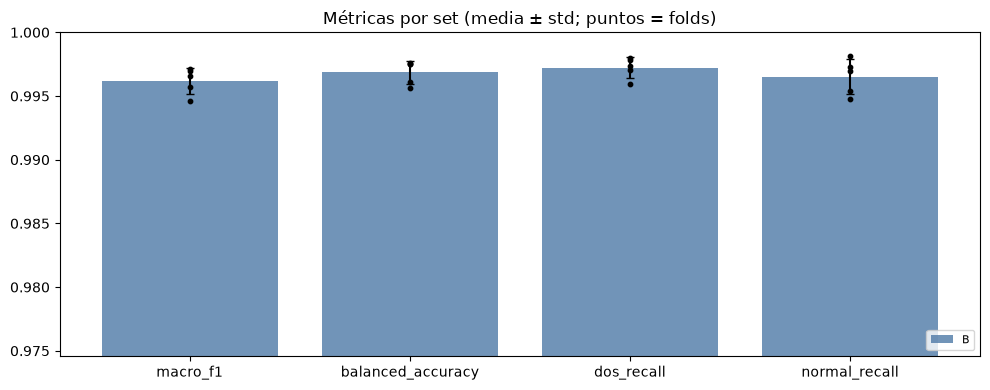

In [5]:
cv_folds, oof_pred, oof_proba, cv_importances = ev.cross_validate_oof(
    X_tcp, y, captures, SPLITS, seed=SEED)
cv_summary = pd.DataFrame({'media': cv_folds.mean(), 'std': cv_folds.std()})
display(cv_folds.round(4))
display(cv_summary.round(4).T)
ev.plot_fold_metrics(cv_folds.assign(set='B').reset_index())

### 2.1 Errores: matriz de confusión y FP por captura

El normal de `DoS.csv` es el más difícil: convive en el tiempo con el ataque y en la
vista `mqtt` tiene pocos frames (969).

,frames,DoS,macro_f1,balanced_accuracy,dos_recall,dos_precision,normal_recall,roc_auc,fp_DoS,fp_Intrusion,fp_MitM
B (vista mqtt),61654.0,45330.0,0.9962,0.9969,0.9972,0.9987,0.9965,0.9999,0.0268,0.0009,0.0031


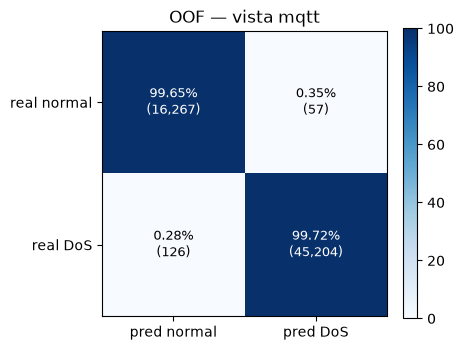

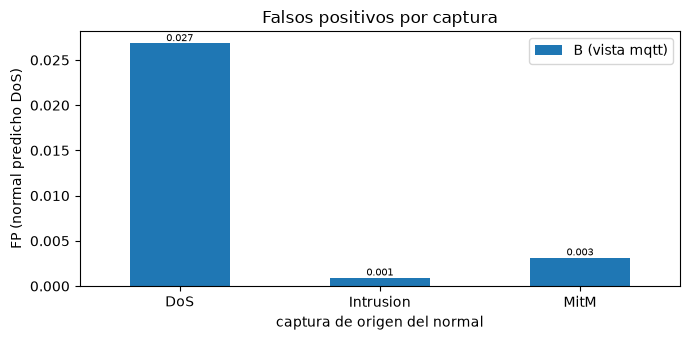

In [6]:
oof_metrics = ev.subset_metrics(y, oof_pred, oof_proba, captures,
                                {'B (vista mqtt)': np.ones(len(y), bool)})
display(oof_metrics.round(4))
counts, share = ev.confusion_table(y, oof_pred)
ev.plot_confusion(share, counts, 'OOF — vista mqtt')
ev.plot_fp_by_capture(oof_metrics)

### 2.2 Importancia de features

Una feature con más del 50 % del peso indica que el modelo depende de una sola señal.

,B
tcp_new_conns_5s,0.5445
frame.len,0.2224
tcp_len_std_5s,0.0962
tcp_bytes_5s,0.0363
fe_log_len,0.0220
frame.time_delta,0.0214
tcp_asymmetry_5s,0.0206
tcp_iat_std_5s,0.0124
tcp_iat,0.0094
fe_is_broker_to_client,0.0090


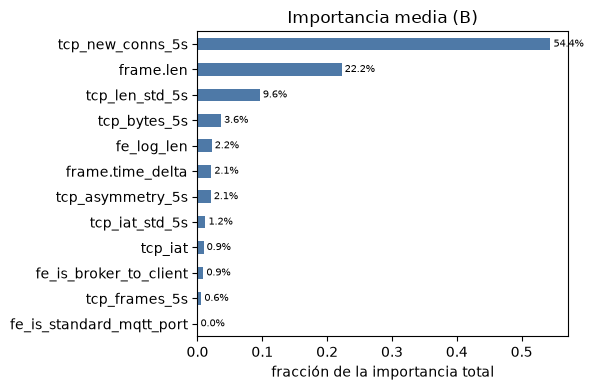

In [7]:
cv_importance = ev.mean_importance({'B': cv_importances})
display((cv_importance / cv_importance.sum()).sort_values('B', ascending=False).round(4))
ev.plot_importance(cv_importance, top=12)

## 3. Ablaciones de B

`tcp_new_conns_5s` concentra la mayor parte de la importancia y el único DoS grabado
es un flood de conexiones nuevas. Se mide cuánto pierde B sin esa feature y sin
`tcp_asymmetry_5s`. A (13 features MQTT) aparece solo como referencia; todos los sets
usan los mismos folds e hiperparámetros.

**Criterio:** si B cae > 0,03 al quitar una feature, depende de ella; entre 0,01 y
0,03 pierde algo; por debajo de 0,01 la señal está repartida.

### 3.1 Vista `mqtt` (alcance del modelo final)

In [8]:
scope_sets = {'A': build_feature_matrix(df_train),
              **ev.ablation_sets(X_tcp, [['tcp_new_conns_5s'],
                                         ['tcp_new_conns_5s', 'tcp_asymmetry_5s']])}
scope_folds, scope_importances = ev.compare_feature_sets(
    scope_sets, y, captures, SPLITS, seed=SEED)
_, scope_means = ev.summarize_folds(scope_folds)
display(scope_means.round(4))
scope_deltas = ev.ablation_deltas(scope_means)
display(scope_deltas.round(4))

,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_Intrusion,fp_MitM
set,,,,,,,,,
A,0.9778,0.9836,0.9987,0.9813,0.9948,0.9858,0.0881,0.0114,0.0107
B,0.9962,0.9969,0.9999,0.9972,0.9987,0.9965,0.0344,0.0011,0.0023
B sin tcp_new_conns_5s,0.9910,0.9924,0.9996,0.9937,0.9968,0.9912,0.0715,0.0084,0.0059
B sin tcp_new_conns_5s y tcp_asymmetry_5s,0.9862,0.9892,0.9993,0.9892,0.9961,0.9892,0.0725,0.0093,0.0072


,macro_f1,caída vs B,ventaja sobre A,lectura
set,,,,
A,0.9778,0.0184,0.0000,comparación (no es ablación)
B,0.9962,0.0000,0.0184,referencia
B sin tcp_new_conns_5s,0.9910,0.0051,0.0133,robusto: la señal está repartida
B sin tcp_new_conns_5s y tcp_asymmetry_5s,0.9862,0.0100,0.0084,robusto: la señal está repartida


Importancia de las variantes: si sin `tcp_new_conns_5s` el peso pasa a otra única
feature, B sigue dependiendo de una sola señal.

,B sin tcp_new_conns_5s,B sin tcp_new_conns_5s y tcp_asymmetry_5s
frame.len,0.4322,0.4288
tcp_len_std_5s,0.1899,0.1472
fe_log_len,0.1449,0.2472
frame.time_delta,0.0680,0.0811
tcp_asymmetry_5s,0.0536,NaN
tcp_iat_std_5s,0.0305,0.0081
tcp_iat,0.0270,0.0279
tcp_bytes_5s,0.0230,0.0214
fe_is_broker_to_client,0.0181,0.0226
tcp_frames_5s,0.0130,0.0156


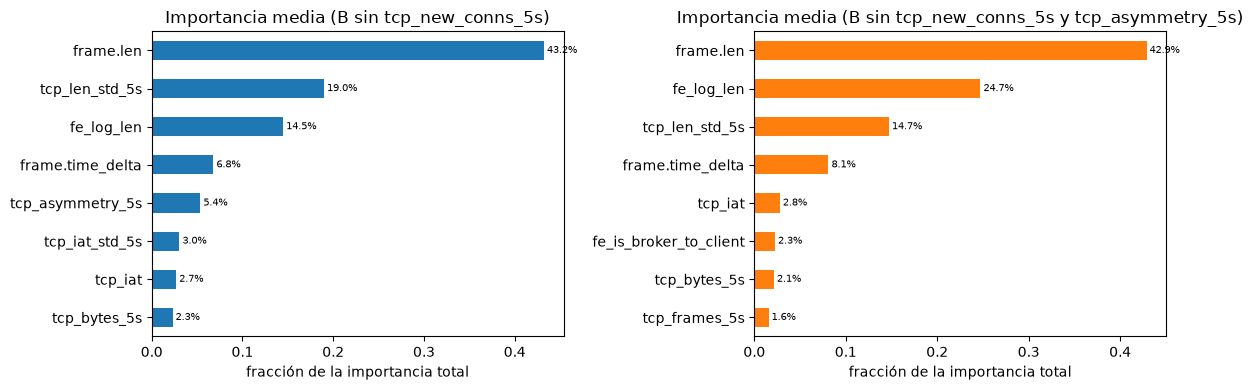

In [9]:
variant_importance = ev.mean_importance(
    {name: frames for name, frames in scope_importances.items() if name.startswith('B sin')})
display((variant_importance / variant_importance.sum()).round(4)
        .sort_values(variant_importance.columns[0], ascending=False))
ev.plot_importance(variant_importance, top=8)

### 3.2 Todo el tráfico (referencia): B vs B sin `tcp_new_conns_5s`

Misma ablación sobre `df_raw` completo, solo como referencia frente al notebook
original. Aquí B puede apoyarse en el atajo de protocolo (sección 4).

,macro_f1,caída vs B,ventaja sobre A,lectura
set,,,,
A,0.9915,0.0066,0.0000,comparación (no es ablación)
B,0.9981,0.0000,0.0066,referencia
B sin tcp_new_conns_5s,0.9953,0.0028,0.0038,robusto: la señal está repartida


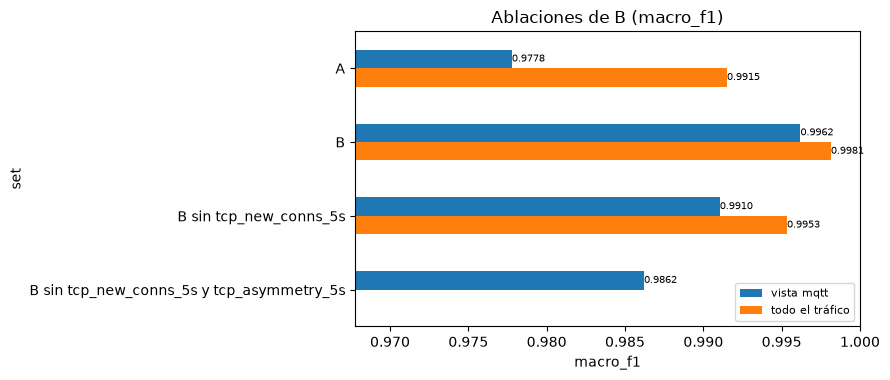

In [10]:
full_labels = ev.binary_labels(df_raw)
full_captures = df_raw['_capture'].to_numpy()
FULL_N_SPLITS, FULL_SPLITS = ev.find_grouped_splits(
    full_labels, pd.factorize(df_raw['_connection'], sort=False)[0], full_captures,
    required_normal_captures=set(full_captures[full_labels == 0]), max_splits=5, seed=SEED)
X_full_b = build_tcp_features(df_raw)

full_sets = {'A': build_feature_matrix(df_raw),
             **ev.ablation_sets(X_full_b, [['tcp_new_conns_5s']])}
full_folds, _ = ev.compare_feature_sets(full_sets, full_labels, full_captures,
                                        FULL_SPLITS, seed=SEED)
_, full_means = ev.summarize_folds(full_folds)
full_deltas = ev.ablation_deltas(full_means)
display(full_deltas.round(4))
ev.plot_ablation({'vista mqtt': scope_means, 'todo el tráfico': full_means})

### 3.3 AUC univariada: señal vs atajo de protocolo

Una feature con AUC alta en todo el tráfico y baja en la vista `mqtt` separa "normal
no-MQTT" de "DoS MQTT", no DoS de normal.

,AUC todo el tráfico,dir todo el tráfico,AUC vista mqtt,dir vista mqtt,caída
feature,,,,,
tcp_new_conns_5s,0.9619,+,0.9591,+,0.0028
tcp_iat,0.8623,-,0.9322,-,-0.0700
frame.len,0.7100,+,0.9251,+,-0.2151
fe_log_len,0.7100,+,0.9251,+,-0.2151
tcp_bytes_5s,0.6305,+,0.9142,+,-0.2837
tcp_len_std_5s,0.6916,+,0.9117,+,-0.2201
frame.time_delta,0.6229,-,0.9090,-,-0.2861
tcp_frames_5s,0.5660,+,0.8831,+,-0.3171
tcp_asymmetry_5s,0.9702,+,0.8292,+,0.1410


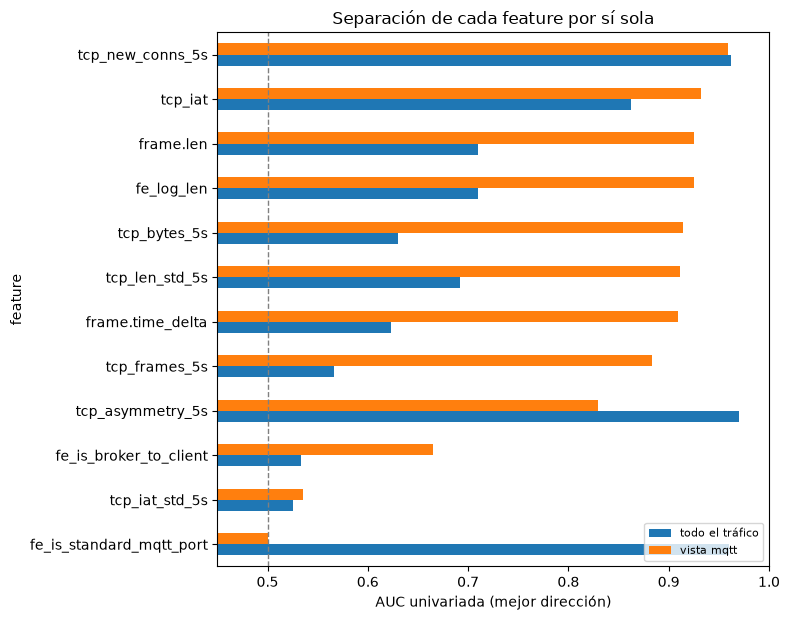

In [11]:
auc_table = ev.univariate_auc_table({'todo el tráfico': (X_full_b, full_labels),
                                     'vista mqtt': (X_tcp, y)})
display(auc_table.round(4))
ev.plot_univariate_auc(auc_table)

## 4. Por qué no entrenar con todo el tráfico

Se entrena el mismo B con validación cruzada sobre `df_raw` completo y se miden sus
predicciones *out-of-fold* **solo sobre los frames de la vista `mqtt`**, que es lo que
verá el agente. Se compara con el modelo de la sección 2 y con la importancia de cada
uno: si el modelo entrenado con todo el tráfico se apoya en `fe_is_standard_mqtt_port`
y `tcp_asymmetry_5s`, está aprendiendo "va al broker" y no "es DoS".

Evaluación OOF sobre los frames de la vista mqtt:


,frames,DoS,macro_f1,balanced_accuracy,dos_recall,dos_precision,normal_recall,roc_auc,fp_DoS,fp_Intrusion,fp_MitM
entrenado con vista mqtt,61654.0,45330.0,0.9962,0.9969,0.9972,0.9987,0.9965,0.9999,0.0268,0.0009,0.0031
entrenado con todo el tráfico,61654.0,45330.0,0.9958,0.9947,0.9990,0.9966,0.9905,0.9999,0.0722,0.0051,0.0060


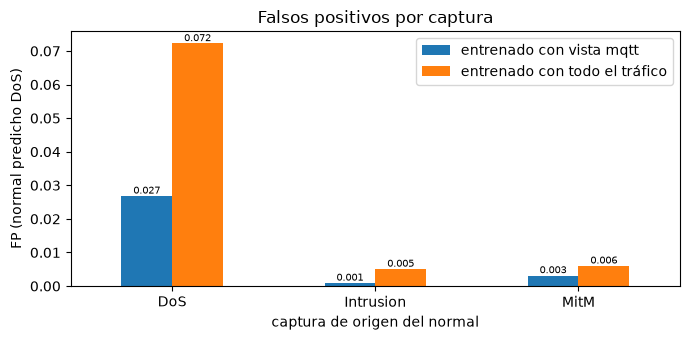

,entrenado con vista mqtt,entrenado con todo el tráfico
tcp_asymmetry_5s,0.0206,0.6199
tcp_new_conns_5s,0.5445,0.2073
fe_is_standard_mqtt_port,0.0000,0.1084
fe_is_broker_to_client,0.0090,0.0108
frame.time_delta,0.0214,0.0100
tcp_iat,0.0094,0.0092
frame.len,0.2224,0.0076
tcp_iat_std_5s,0.0124,0.0071
tcp_bytes_5s,0.0363,0.0067
tcp_frames_5s,0.0059,0.0061


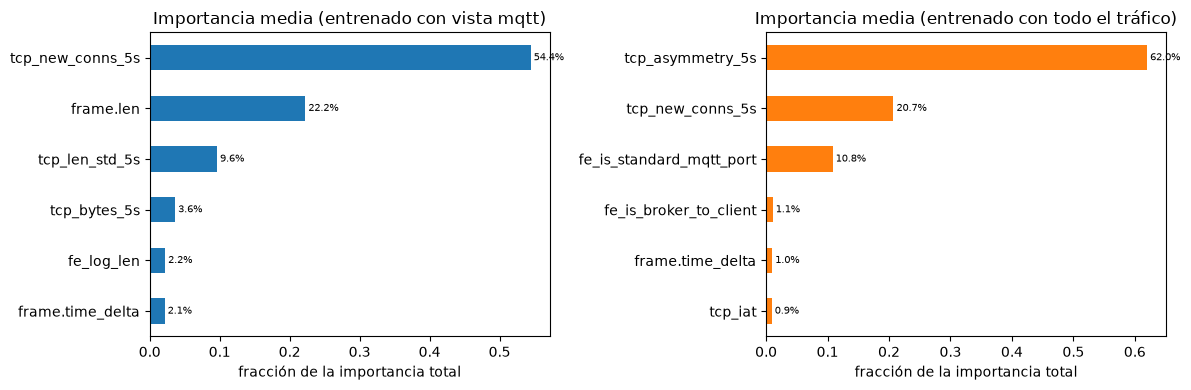

In [12]:
_, full_pred, full_proba, full_importances = ev.cross_validate_oof(
    X_full_b, full_labels, full_captures, FULL_SPLITS, seed=SEED)
in_scope = df_raw.index.isin(df_train.index)
training_comparison = pd.concat([
    oof_metrics.rename(index={'B (vista mqtt)': 'entrenado con vista mqtt'}),
    ev.subset_metrics(full_labels[in_scope], full_pred[in_scope], full_proba[in_scope],
                      full_captures[in_scope], {'entrenado con todo el tráfico':
                                                np.ones(int(in_scope.sum()), bool)}),
])
print('Evaluación OOF sobre los frames de la vista mqtt:')
display(training_comparison.round(4))
ev.plot_fp_by_capture(training_comparison)

importance_comparison = ev.mean_importance({'entrenado con vista mqtt': cv_importances,
                                            'entrenado con todo el tráfico': full_importances})
display((importance_comparison / importance_comparison.sum()).round(4)
        .sort_values('entrenado con todo el tráfico', ascending=False))
ev.plot_importance(importance_comparison, top=6)

## 5. Modelo final y exportación

Refit sobre **toda la vista `mqtt`** con los mismos hiperparámetros y pesos. Las métricas
exportadas son las de la validación cruzada (sección 2). `pipeline_config.json` declara
`training_scope = mqtt_ports`: el agente solo debe clasificar frames con puerto
1883/8883 y calcular las ventanas TCP solo con esos frames.

In [13]:
final_model = ev.fit_balanced(X_tcp, y, seed=SEED)
metrics = {
    'training_scope': 'mqtt_ports',
    'cv': {'n_splits': N_SPLITS, 'folds': cv_folds, 'mean': cv_summary['media'],
           'std': cv_summary['std']},
    'oof': oof_metrics,
    'importance': cv_importance['B'] / cv_importance['B'].sum(),
    'ablation_scope': {'means': scope_means, 'deltas': scope_deltas},
    'ablation_full_reference': {'n_splits': FULL_N_SPLITS, 'means': full_means,
                                'deltas': full_deltas},
    'univariate_auc': auc_table,
    'training_scope_comparison': training_comparison,
}
model_manifest = export.export_tcp_model(
    final_model, MODEL_DIR, df=df_train, features=X_tcp, splits=SPLITS, metrics=metrics,
    source_manifest=source_manifest, seed=SEED, window_seconds=WINDOW_SECONDS,
    training_scope='mqtt_ports')
print(f'Exportado en {MODEL_DIR.relative_to(REPO_ROOT)}/ ({model_manifest["version"]}, '
      f'{model_manifest["training_rows"]:,} frames)')
display(pd.Series(model_manifest['files'], name='sha256').to_frame())

Exportado en modelos_agente_tcp/ (tcp-B-v2, 61,654 frames)


,sha256
xgb_tcp.ubj,f9260bc82a6e1ed51601a657212d67e823336a8d01eb20...
le_target.joblib,4b027febf1f9ba0489d801aa85416d79c2e5f0a6004d48...
pipeline_config.json,eb4e5aa0a32d3dc4305192ad9ddb029ebfd021dd49e37e...
metrics.json,ccaf6aeb94e4b82b14c5e314ead9dd8985d8d3a0270f00...
evaluation_split.json,987bd9cc36727d6d648f05ee2aa815bc6ccfe73447b44b...


## 6. Validación de los artefactos

Se recargan `xgb_tcp.ubj`, `le_target.joblib` y `pipeline_config.json` y se comparan
las probabilidades con el modelo en memoria sobre una muestra estratificada por clase.

In [14]:
rng = np.random.default_rng(SEED)
sample_idx = np.concatenate([rng.choice(np.where(y == k)[0], min(5000, int((y == k).sum())),
                                        replace=False) for k in (0, 1)])
checks, EXPORT_OK = export.validate_export(MODEL_DIR, final_model, X_tcp.iloc[sample_idx],
                                           TCP_FEATURE_COLUMNS)
display(checks)
print('Validación:', 'OK — listo para integrar' if EXPORT_OK else 'FALLA — no integrar')

,ok
check,
archivos presentes,True
hashes del manifiesto,True
columnas = TCP_FEATURE_COLUMNS,True
nombres del booster = columnas,True
class_names y normal_idx,True
"probabilidades idénticas (10,000 frames)",True
etiquetas en class_names,True
sin features mqtt.*,True


Validación: OK — listo para integrar


## 7. Conclusión

**Modelo final.** XGBoost con las 12 features TCP, entrenado con la vista `mqtt`
(61.654 frames, el 99,7 % del DoS). En validación cruzada agrupada por conexión obtiene
macro-F1 0,9962 ± 0,0010, recall de DoS 0,9972 y recall del normal 0,9965. Los
artefactos de `modelos_agente_tcp/` (`tcp-B-v2`) recargan y predicen igual que el modelo
en memoria.

**Por qué la vista `mqtt` y no todo el tráfico (sección 4).** Evaluados sobre los mismos
frames del broker, los dos modelos tienen un macro-F1 casi igual (0,9962 vs 0,9958),
pero el entrenado con todo el tráfico:
- marca como DoS el 7,2 % del normal de `DoS.csv`, frente al 2,7 % del entrenado con la
  vista `mqtt`, y también tiene más FP en MitM e Intrusion;
- pone el 73 % de su importancia en `tcp_asymmetry_5s` y `fe_is_standard_mqtt_port`,
  dos features que dentro de la vista `mqtt` casi no separan (AUC 0,83 y 0,50). Aprendió
  "va al broker", no "es DoS".

El modelo final se apoya en `tcp_new_conns_5s`, `frame.len`, `tcp_len_std_5s` y los
conteos por ventana, y `fe_is_standard_mqtt_port` tiene importancia 0.

**Ablaciones.** Sin `tcp_new_conns_5s` el modelo cae 0,0051, y sin esa feature ni
`tcp_asymmetry_5s` cae 0,0100. Todas las variantes siguen por encima de A (0,9778): la
señal está repartida.

**Límites.**
- `tcp_new_conns_5s` concentra el 54 % de la importancia. El único DoS grabado es un
  flood de conexiones nuevas, y un DoS sobre conexiones persistentes no activaría esa
  feature. Las ablaciones indican que el modelo seguiría detectando por tamaño y ritmo,
  pero hay que confirmarlo con el simulador.
- Una sola captura DoS: las métricas valen para ese escenario. Falta validar en caliente
  con conexiones persistentes, otras tasas, clientes y payloads, y TLS en 8883.
- El agente debe clasificar solo frames con puerto 1883/8883 y calcular las ventanas TCP
  solo con esos frames (`training_scope = mqtt_ports` en `pipeline_config.json`). Para
  integrarlo faltan el builder incremental TCP y el adaptador `TcpXgbClassifier`.
  `modelos_agente/` no se ha modificado.